# Divergence clipping test (FM)

Does FM work better when the strands at high-divergence places (partings, whorls) are taken out first?

1. Pick a random mid- or long-hair case (hairstyle + initial mask) of the `hl_n50_s0` benchmark and compute the divergence of the
   hair flow field: the 3D net outward flux of every grid cell (`update_contour.cal_grid_flux_3d`).
   **Divergence of a strand = |flux| of its root cell.**
2. Two clipped versions:
   - **clip1**: erase the strands in the top `TOP_PCT` % of divergence (default 10 %).
   - **clip2**: erase the strands with divergence > `DIV_THRESHOLD` (default 0.3).
3. Run FM (projection overlap, the benchmark's `fm_proj_lam1000` setting) on **original**, **clip1** and
   **clip2**. Erased strands are not part of the FM graph (induced subgraph of the projection graph), are not
   rendered and are not scored.
4. **Restore**: put the erased strands of clip1 / clip2 back. Each one takes the **mode of the labels of the
   strands it intersects** (its neighbors in the projection graph, each weighted by the number of cells where
   the pair crosses), counting only kept strands, whose labels FM has fixed. Ties and strands with no kept
   neighbor fall back to their root-cell mask label.
   Then render and score again, and compare with the original FM.

Grid score = `metrics.grid_score` of the benchmark (convex-hull overlap of highlight vs base per cell, lower =
less mixed). `mean_all` averages over all cells; `per_black_area` / `per_white_area` divide the total score by
the highlight / base area.

Outputs (strand masks, metrics, renders) go to `data/divergence_clip/<case>/`. Renders that already exist are
reused, so rerunning the notebook is cheap.

In [1]:
import os, sys, json, time
import numpy as np
import numba as nb
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
%matplotlib inline

PROJECT_ROOT = "/home/kyh/Desktop/P76154862"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.environ.setdefault("TQDM_DISABLE", "1")

# common sets CUDA_VISIBLE_DEVICES="" on import: no GPU in python (Blender renders still use the GPU)
from highlighting.generate_from_3D_models.contour_algo_test import common, metrics as M
from highlighting.generate_from_3D_models.contour_algo_test.context import CaseContext
from highlighting.generate_from_3D_models.contour_algo_test.methods import MethodResult
from highlighting.generate_from_3D_models.contour_algo_test.render_results import _render_device
import highlighting.generate_from_3D_models.update_contour as uc
from highlighting.generate_from_3D_models.mask_analysis import plots, render as ma_render

# ---------------------------------------------------------------- parameters
BENCH_DIR = os.path.join(common.BENCH_DIR, "data", "hl_n50_s0")
CASE_ID = None          # None = random case (PICK_SEED) among LENGTH_CLASSES; or e.g. "case_0042"
PICK_SEED = 1
LENGTH_CLASSES = ("mid", "long")   # hair length classes the random pick draws from
TOP_PCT = 10.0          # clip1: erase the top TOP_PCT % strands by divergence
DIV_THRESHOLD = 0.3     # clip2: erase strands with divergence > DIV_THRESHOLD
LAM, MAX_PASSES, BALANCE_TOL = 1000, 3, 0.02   # = fm_proj_lam1000
MAX_STRANDS = None      # None = all strands (as the hl_n50_s0 run; the projection graph is in the disk cache)
RENDER = True
RENDER_DEVICE = "gpu"   # "gpu" | "cpu"
OVERWRITE_RENDER = False
OUT_ROOT = os.path.join(common.BENCH_DIR, "data", "divergence_clip")
GRAPH_CACHE = os.path.join(common.BENCH_DIR, "data", "graph_cache")
plots.setup_cjk_font()

## 1. Case and divergence

In [2]:
cases = sorted(c for c in os.listdir(os.path.join(BENCH_DIR, "cases")) if c.startswith("case_"))
cases = [c for c in cases if common.read_json(os.path.join(BENCH_DIR, "cases", c, "case.json"))
         ["hairstyle"]["length_class"] in LENGTH_CLASSES]
if CASE_ID is None:
    CASE_ID = cases[np.random.default_rng(PICK_SEED).integers(len(cases))]
print(f"{len(cases)} {'/'.join(LENGTH_CLASSES)} cases, picked {CASE_ID}")
case = common.read_json(os.path.join(BENCH_DIR, "cases", CASE_ID, "case.json"))
bench = common.read_json(os.path.join(BENCH_DIR, "benchmark.json"))
NPZ = case["hairstyle"]["npz_path"]
OUT = os.path.join(OUT_ROOT, CASE_ID)
os.makedirs(OUT, exist_ok=True)

t0 = time.time()
hair = common.load_hairstyle(NPZ, MAX_STRANDS, seed=case["seed"])
mask = np.load(os.path.join(BENCH_DIR, "cases", CASE_ID, case["mask_file"]))
grid = common.scalp_grid(case["grid_n"], bench["dataset_path"])
cc = CaseContext(hair, mask, grid, graph_cache_dir=GRAPH_CACHE)
g = cc.g
S = cc.n_strands
print(f"{CASE_ID}: {case['hairstyle']['name']} ({case['hairstyle']['length_class']}, median length "
      f"{case['hairstyle']['median_length']} m), mask {case['mask_generator']}, {S} strands, "
      f"highlight strand frac {cc.init_state.mean():.3f}  [{time.time() - t0:.1f} s]")

40 mid/long cases, picked case_0025


case_0025: base_20_idx_51928 (long, median length 0.237 m), mask polygon, 94257 strands, highlight strand frac 0.081  [0.5 s]


In [3]:
t0 = time.time()
flux, flux_ok = uc.cal_grid_flux_3d(cc.positions, g["grid_pos"], g["grid_normal"], g["grid_valid"], g["half_size"],
                                    cc.smg, grid_t1=g["grid_t1"], grid_t2=g["grid_t2"], show_progress=False)
div_map = np.abs(flux)                                  # (n, n) (row, col)
strand_div = div_map[cc.row_idx, cc.col_idx]           # (S,) divergence of every strand = |flux| of its root cell
print(f"flux in {time.time() - t0:.1f} s; strand divergence percentiles 50/90/95/99:",
      np.percentile(strand_div, [50, 90, 95, 99]).round(3))

flux in 5.9 s; strand divergence percentiles 50/90/95/99: [0.037 0.128 0.195 1.12 ]


## 2. clip1 / clip2

The divergence is constant inside a cell, so clip1 erases whole cells: every strand whose divergence is at
least the (100 − TOP_PCT) percentile. The erased share can be a bit above TOP_PCT because of these ties.

clip1: top 10% (|flux| >= 0.128): erase 9464 strands (10.0%) rooted in 63 cells; of them highlight 2.9% (all strands: 8.1%)
clip2: |flux| > 0.3: erase 3358 strands (3.6%) rooted in 21 cells; of them highlight 0.0% (all strands: 8.1%)


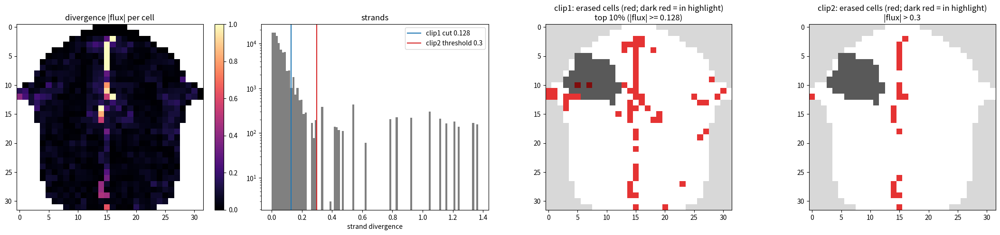

In [4]:
cut1 = float(np.percentile(strand_div, 100 - TOP_PCT))
REMOVED = {
    "clip1": strand_div >= cut1,
    "clip2": strand_div > DIV_THRESHOLD,
}
CLIP_DESC = {"clip1": f"top {TOP_PCT:g}% (|flux| >= {cut1:.3f})", "clip2": f"|flux| > {DIV_THRESHOLD:g}"}
for k, r in REMOVED.items():
    cells = np.unique(cc.row_idx[r] * cc.n + cc.col_idx[r]).size
    print(f"{k}: {CLIP_DESC[k]}: erase {r.sum()} strands ({r.mean():.1%}) rooted in {cells} cells; "
          f"of them highlight {cc.init_state[r].mean():.1%} (all strands: {cc.init_state.mean():.1%})")

valid = grid.valid_rc
fig, ax = plt.subplots(1, 4, figsize=(22, 5))
im = ax[0].imshow(np.where(valid, div_map, np.nan), cmap="magma", vmin=0, vmax=1)
fig.colorbar(im, ax=ax[0], fraction=0.046); ax[0].set_title("divergence |flux| per cell")
ax[1].hist(strand_div, bins=100, color="gray")
ax[1].axvline(cut1, color="tab:blue", label=f"clip1 cut {cut1:.3f}")
ax[1].axvline(DIV_THRESHOLD, color="tab:red", label=f"clip2 threshold {DIV_THRESHOLD}")
ax[1].set_yscale("log"); ax[1].set_xlabel("strand divergence"); ax[1].legend(); ax[1].set_title("strands")
for a, k in zip(ax[2:], REMOVED):
    rm_cells = np.zeros((cc.n, cc.n), bool); rm_cells[cc.row_idx[REMOVED[k]], cc.col_idx[REMOVED[k]]] = True
    img = np.ones((cc.n, cc.n, 3)) * 0.85
    img[valid] = 1.0
    img[cc.mask & valid] = (0.35, 0.35, 0.35)
    img[rm_cells] = (0.9, 0.2, 0.2)
    img[rm_cells & cc.mask] = (0.5, 0.05, 0.05)
    a.imshow(img); a.set_title(f"{k}: erased cells (red; dark red = in highlight)\n{CLIP_DESC[k]}")
plt.tight_layout(); fig.savefig(os.path.join(OUT, "divergence_clip.png"), dpi=90); plt.show()

## 3. FM on original / clip1 / clip2

The clipped FM runs on the induced subgraph of the projection graph over the kept strands (a pair's crossing
count does not depend on the other strands, so this equals rebuilding the graph without the erased strands).
`fm_original` should match the benchmark's `fm_proj_lam1000` result exactly (checked below when it exists).

In [5]:
G = cc.incidence("projection")
print(f"projection graph: {G.n_strands} strands, {G.n_edges} pairs  {cc.timings}")


@nb.njit(cache=True)
def _sub_degree(ptr, nbr, keep, new_id, deg):
    for v in range(ptr.shape[0] - 1):
        if keep[v]:
            c = 0
            for e in range(ptr[v], ptr[v + 1]):
                if keep[nbr[e]]:
                    c += 1
            deg[new_id[v]] = c


@nb.njit(cache=True)
def _sub_fill(ptr, nbr, weight, keep, new_id, sptr, snbr, sw):
    for v in range(ptr.shape[0] - 1):
        if keep[v]:
            j = sptr[new_id[v]]
            for e in range(ptr[v], ptr[v + 1]):
                u = nbr[e]
                if keep[u]:
                    snbr[j] = new_id[u]
                    sw[j] = weight[e]
                    j += 1


def induced_subgraph(G, keep):
    # StrandGraph over the kept strands only (renumbered in order)
    keep = np.ascontiguousarray(keep, dtype=np.bool_)
    new_id = np.cumsum(keep) - 1
    deg = np.zeros(int(keep.sum()), np.int64)
    _sub_degree(G.ptr, G.nbr, keep, new_id, deg)
    sptr = np.zeros(deg.size + 1, np.int64); np.cumsum(deg, out=sptr[1:])
    snbr = np.empty(sptr[-1], G.nbr.dtype); sw = np.empty(sptr[-1], G.weight.dtype)
    _sub_fill(G.ptr, G.nbr, G.weight, keep, new_id, sptr, snbr, sw)
    return uc.StrandGraph(sptr, snbr, sw)


def run_fm(graph, init):
    t0 = time.time()
    hist = uc.fm_refine(graph, init, mode="clique", lam=LAM, max_passes=MAX_PASSES, balance_tol=BALANCE_TOL,
                        verbose=False, return_history=True)
    return hist[-1], dict(n_passes=len(hist) - 1, seconds=round(time.time() - t0, 2),
                          pass_flip_ratios=[float((b != a).mean()) for a, b in zip(hist[:-1], hist[1:])])


RESULTS, INFO = {}, {}
RESULTS["mask_only"] = MethodResult(strand_mask=cc.init_state.copy())
INFO["mask_only"] = {}

state, INFO["fm_original"] = run_fm(G, cc.init_state)
RESULTS["fm_original"] = MethodResult(strand_mask=state)

for k, removed in REMOVED.items():
    keep = ~removed
    sub = induced_subgraph(G, keep)
    sub_state, info = run_fm(sub, cc.init_state[keep])
    full = cc.init_state.copy(); full[keep] = sub_state            # erased strands: hidden, label unused
    RESULTS[f"fm_{k}"] = MethodResult(strand_mask=full, hidden=removed.copy())
    INFO[f"fm_{k}"] = dict(info, sub_pairs=int(sub.n_edges), erased=int(removed.sum()))
    del sub
for k, v in INFO.items():
    print(k, v)

ref = os.path.join(BENCH_DIR, "runs", "run", "cases", CASE_ID, "fm_proj_lam1000", "maps.npz")
if MAX_STRANDS is None and os.path.exists(ref):
    same = np.array_equal(np.load(ref)["strand_mask"], RESULTS["fm_original"].strand_mask)
    print("fm_original == benchmark fm_proj_lam1000:", same)

    graph cache: loaded projection (293072494 pairs) in 1.2s
projection graph: 94257 strands, 293072494 pairs  {'membership': 0.34, 'incidence_projection_load': 1.24}


mask_only {}
fm_original {'n_passes': 3, 'seconds': 9.02, 'pass_flip_ratios': [0.05999554409752061, 0.1031647516895297, 0.0006153389138207242]}
fm_clip1 {'n_passes': 3, 'seconds': 7.47, 'pass_flip_ratios': [0.05685610840517496, 0.10993832038022007, 0.0026181406484025805], 'sub_pairs': 239599267, 'erased': 9464}
fm_clip2 {'n_passes': 3, 'seconds': 8.08, 'pass_flip_ratios': [0.05976963442942167, 0.11102432369993069, 0.005324591029604286], 'sub_pairs': 274549503, 'erased': 3358}
fm_original == benchmark fm_proj_lam1000: True


### Scores

mask_only: scored in 7.7 s


fm_original: scored in 7.2 s


fm_clip1: scored in 6.6 s


fm_clip2: scored in 6.9 s


| variant | grid_score.mean_all | grid_score.per_black_area | grid_score.per_white_area | grid_score.mixed_mean | projection.cut_pairs | projection.cut_weight | strands.flip_frac | strands.hidden | strands.visible_highlight | strands.visible_base |
|---|---|---|---|---|---|---|---|---|---|---|
| mask_only | 0.13129 | 3.27910 | 0.20126 | 0.81481 | 22351750 | 43551940 | 0.00000 | 0 | 7640 | 86617 |
| fm_original | 0.08146 | 2.19521 | 0.12432 | 0.36587 | 2470289 | 3787442 | 0.13237 | 0 | 5755 | 88502 |
| fm_clip1 | 0.08619 | 1.91876 | 0.13394 | 0.37242 | 2978579 | 4446724 | 0.12728 | 9464 | 5671 | 79122 |
| fm_clip2 | 0.06703 | 1.52528 | 0.10384 | 0.42109 | 2670014 | 3916805 | 0.13384 | 3358 | 5823 | 85076 |

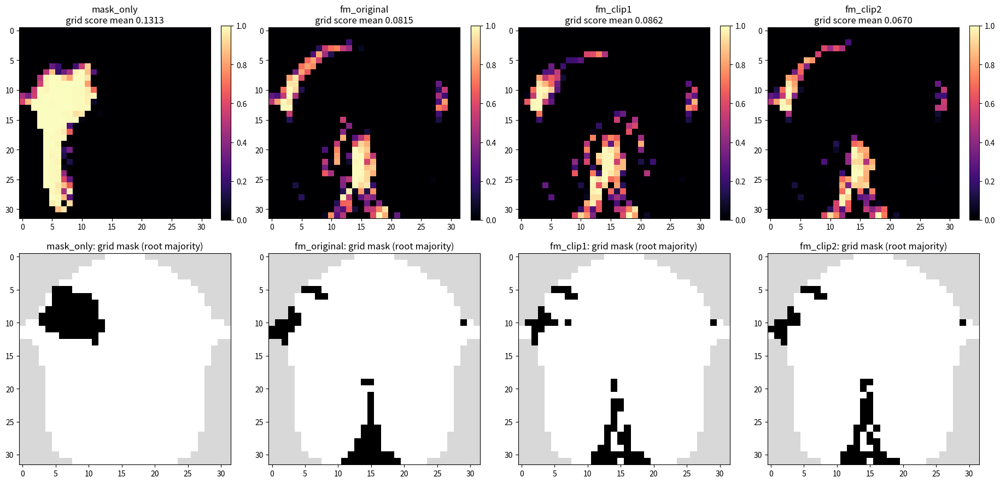

In [6]:
METRIC_NAMES = ("strands", "projection", "grid_score", "shape")
SCORES, MAPS = {}, {}


def evaluate(name):
    t0 = time.time()
    SCORES[name], MAPS[name], _ = M.evaluate(cc, RESULTS[name], METRIC_NAMES)
    r = RESULTS[name]
    os.makedirs(os.path.join(OUT, name), exist_ok=True)
    np.savez_compressed(os.path.join(OUT, name, "maps.npz"), strand_mask=r.strand_mask, strand_idx=hair["strand_idx"],
                        **({"hidden": r.hidden} if r.hidden is not None else {}), **MAPS[name])
    print(f"{name}: scored in {time.time() - t0:.1f} s")


COLS = [("grid_score", "mean_all"), ("grid_score", "per_black_area"), ("grid_score", "per_white_area"),
        ("grid_score", "mixed_mean"), ("projection", "cut_pairs"), ("projection", "cut_weight"),
        ("strands", "flip_frac"), ("strands", "hidden"), ("strands", "visible_highlight"), ("strands", "visible_base")]


def table(names):
    head = "| variant | " + " | ".join(f"{m}.{k}" for m, k in COLS) + " |"
    rows = [head, "|" + "---|" * (len(COLS) + 1)]
    base = SCORES["fm_original"]["grid_score"]["mean_all"] if "fm_original" in SCORES else None
    for n in names:
        s = SCORES[n]
        cells = []
        for m, k in COLS:
            x = s[m][k]
            cells.append(f"{x:.5f}" if isinstance(x, float) else f"{x}")
        rows.append(f"| {n} | " + " | ".join(cells) + " |")
    display(Markdown("\n".join(rows)))


def score_maps(names):
    fig, axes = plt.subplots(2, len(names), figsize=(4.6 * len(names), 9))
    for j, n in enumerate(names):
        sc = MAPS[n]["grid_score/score"]
        im = axes[0, j].imshow(sc, cmap="magma", vmin=0, vmax=1)
        axes[0, j].set_title(f"{n}\ngrid score mean {sc.mean():.4f}")
        fig.colorbar(im, ax=axes[0, j], fraction=0.046)
        gm = MAPS[n]["shape/grid_mask"]
        img = np.ones((cc.n, cc.n, 3)) * 0.85
        img[valid] = 1.0; img[gm & valid] = 0.0
        axes[1, j].imshow(img); axes[1, j].set_title(f"{n}: grid mask (root majority)")
    plt.tight_layout()
    return fig


for n in ("mask_only", "fm_original", "fm_clip1", "fm_clip2"):
    evaluate(n)
table(["mask_only", "fm_original", "fm_clip1", "fm_clip2"])
fig = score_maps(["mask_only", "fm_original", "fm_clip1", "fm_clip2"])
fig.savefig(os.path.join(OUT, "grid_score_fm.png"), dpi=80); plt.show()

## 4. Restore the erased strands (mode of intersections)

For every erased strand i: w_hi = Σ weight(i, j) over kept neighbors j labeled highlight, w_lo the same for
base. Label = highlight if w_hi > w_lo, base if w_lo > w_hi, the root-cell mask label on a tie (also when no kept
strand crosses it). All strands are visible again, so the scores are directly comparable with `fm_original`.

fm_clip1_restored {'restored': 9464, 'no_kept_neighbor': 37, 'ties': 0, 'to_highlight': 1517, 'differs_from_root_mask': 1791}


fm_clip1_restored: scored in 7.2 s
fm_clip2_restored {'restored': 3358, 'no_kept_neighbor': 37, 'ties': 0, 'to_highlight': 771, 'differs_from_root_mask': 771}


fm_clip2_restored: scored in 7.1 s


| variant | grid_score.mean_all | grid_score.per_black_area | grid_score.per_white_area | grid_score.mixed_mean | projection.cut_pairs | projection.cut_weight | strands.flip_frac | strands.hidden | strands.visible_highlight | strands.visible_base |
|---|---|---|---|---|---|---|---|---|---|---|
| mask_only | 0.13129 | 3.27910 | 0.20126 | 0.81481 | 22351750 | 43551940 | 0.00000 | 0 | 7640 | 86617 |
| fm_original | 0.08146 | 2.19521 | 0.12432 | 0.36587 | 2470289 | 3787442 | 0.13237 | 0 | 5755 | 88502 |
| fm_clip1 | 0.08619 | 1.91876 | 0.13394 | 0.37242 | 2978579 | 4446724 | 0.12728 | 9464 | 5671 | 79122 |
| fm_clip1_restored | 0.09840 | 2.28998 | 0.15152 | 0.40629 | 3544305 | 5379472 | 0.14628 | 0 | 7188 | 87069 |
| fm_clip2 | 0.06703 | 1.52528 | 0.10384 | 0.42109 | 2670014 | 3916805 | 0.13384 | 3358 | 5823 | 85076 |
| fm_clip2_restored | 0.06871 | 1.56342 | 0.10595 | 0.42639 | 2960375 | 4416654 | 0.14202 | 0 | 6594 | 87663 |

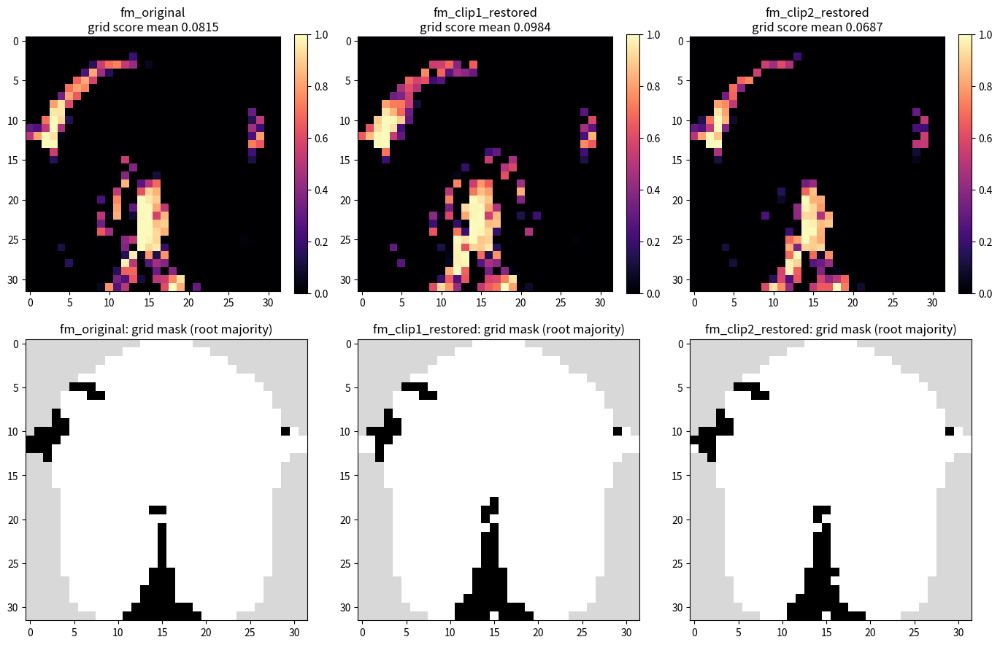

In [7]:
@nb.njit(parallel=True, cache=True)
def _neighbor_votes(ptr, nbr, weight, label, keep, idx, w_hi, w_lo):
    for t in nb.prange(idx.shape[0]):
        v = idx[t]
        hi = 0.0
        lo = 0.0
        for e in range(ptr[v], ptr[v + 1]):
            u = nbr[e]
            if keep[u]:
                if label[u]:
                    hi += weight[e]
                else:
                    lo += weight[e]
        w_hi[t] = hi
        w_lo[t] = lo


def restore(name_fm):
    r = RESULTS[name_fm]
    removed = r.hidden
    idx = np.flatnonzero(removed).astype(np.int64)
    w_hi = np.zeros(idx.size); w_lo = np.zeros(idx.size)
    _neighbor_votes(G.ptr, G.nbr, G.weight, r.strand_mask, ~removed, idx, w_hi, w_lo)
    fallback = cc.init_state[idx]
    lab = np.where(w_hi > w_lo, True, np.where(w_lo > w_hi, False, fallback))
    state = r.strand_mask.copy(); state[idx] = lab
    info = dict(restored=int(idx.size), no_kept_neighbor=int(((w_hi + w_lo) == 0).sum()),
                ties=int(((w_hi == w_lo) & (w_hi > 0)).sum()), to_highlight=int(lab.sum()),
                differs_from_root_mask=int((lab != fallback).sum()))
    return MethodResult(strand_mask=state), info


for k in REMOVED:
    name = f"fm_{k}_restored"
    RESULTS[name], INFO[name] = restore(f"fm_{k}")
    print(name, INFO[name])
    evaluate(name)

ALL = ["mask_only", "fm_original", "fm_clip1", "fm_clip1_restored", "fm_clip2", "fm_clip2_restored"]
table(ALL)
fig = score_maps(["fm_original", "fm_clip1_restored", "fm_clip2_restored"])
fig.savefig(os.path.join(OUT, "grid_score_restored.png"), dpi=80); plt.show()

## 5. Summary (scores)

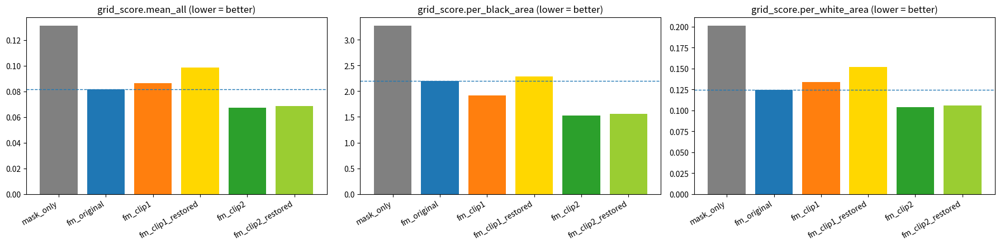

mask_only            grid score mean_all 0.13129  (+61.2% vs fm_original)
fm_original          grid score mean_all 0.08146  (+0.0% vs fm_original)
fm_clip1             grid score mean_all 0.08619  (+5.8% vs fm_original)
fm_clip1_restored    grid score mean_all 0.09840  (+20.8% vs fm_original)
fm_clip2             grid score mean_all 0.06703  (-17.7% vs fm_original)
fm_clip2_restored    grid score mean_all 0.06871  (-15.7% vs fm_original)
saved to /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025


In [8]:
keys = [("grid_score", "mean_all"), ("grid_score", "per_black_area"), ("grid_score", "per_white_area")]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
colors = ["gray", "tab:blue", "tab:orange", "gold", "tab:green", "yellowgreen"]
for ax, (m, k) in zip(axes, keys):
    vals = [SCORES[n][m][k] for n in ALL]
    ax.bar(range(len(ALL)), vals, color=colors)
    ax.set_xticks(range(len(ALL))); ax.set_xticklabels(ALL, rotation=30, ha="right")
    ax.axhline(SCORES["fm_original"][m][k], color="tab:blue", ls="--", lw=1)
    ax.set_title(f"{m}.{k} (lower = better)")
plt.tight_layout(); fig.savefig(os.path.join(OUT, "summary.png"), dpi=90); plt.show()

base = SCORES["fm_original"]["grid_score"]["mean_all"]
for n in ALL:
    x = SCORES[n]["grid_score"]["mean_all"]
    print(f"{n:20s} grid score mean_all {x:.5f}  ({(x - base) / base:+.1%} vs fm_original)")

common.write_json(dict(case=CASE_ID, hairstyle=case["hairstyle"], mask_generator=case["mask_generator"],
                       n_strands=S, max_strands=MAX_STRANDS, top_pct=TOP_PCT, clip1_cut=cut1,
                       div_threshold=DIV_THRESHOLD, lam=LAM, max_passes=MAX_PASSES, balance_tol=BALANCE_TOL,
                       info=INFO, scores=SCORES, finished=common.now_str()),
                  os.path.join(OUT, "summary.json"))
print("saved to", OUT)

## 6. Renders

Last, because this is the slow part: one Blender run per result (front view + multiview, about 20 s each on the
GPU, about 4.5 min on the CPU; 6 results). Everything above is already computed and saved. Base = white, highlight = black; erased strands
(fm_clip1 / fm_clip2) are not rendered. Existing renders are reused unless OVERWRITE_RENDER.

wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/template_notebook_color_matrix.npz
執行 Blender multi-view 渲染...


00:00.249  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:05.868  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
00:08.455  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/front.png'
00:10.643  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/_multiview_tmp.png'
00:12.508  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/_multiview_tmp.png'
00:14.353  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/_m

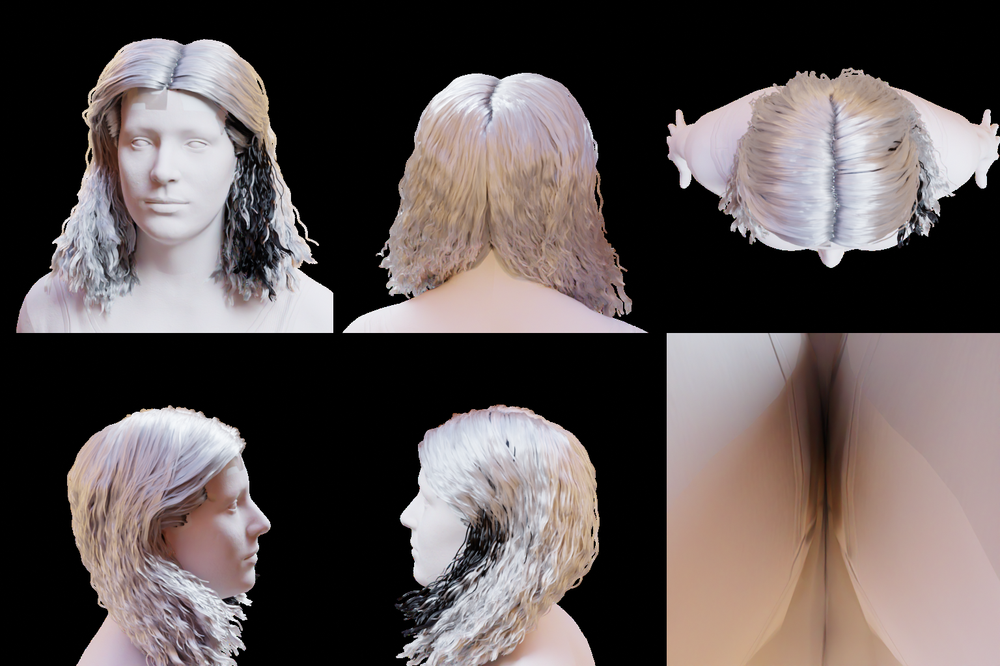

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/render_info.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/scalp_grid_rgb.jpg
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/template_notebook_color_matrix.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/mask_only/render/template_notebook_color_matrix.npz
mask_only: rendered in 20.1 s (gpu), 0 strands left out
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/template_notebook_color_matr

00:00.251  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:05.851  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
00:08.447  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/front.png'
00:10.516  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/_multiview_tmp.png'
00:12.374  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/_multiview_tmp.png'
00:14.265  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/r

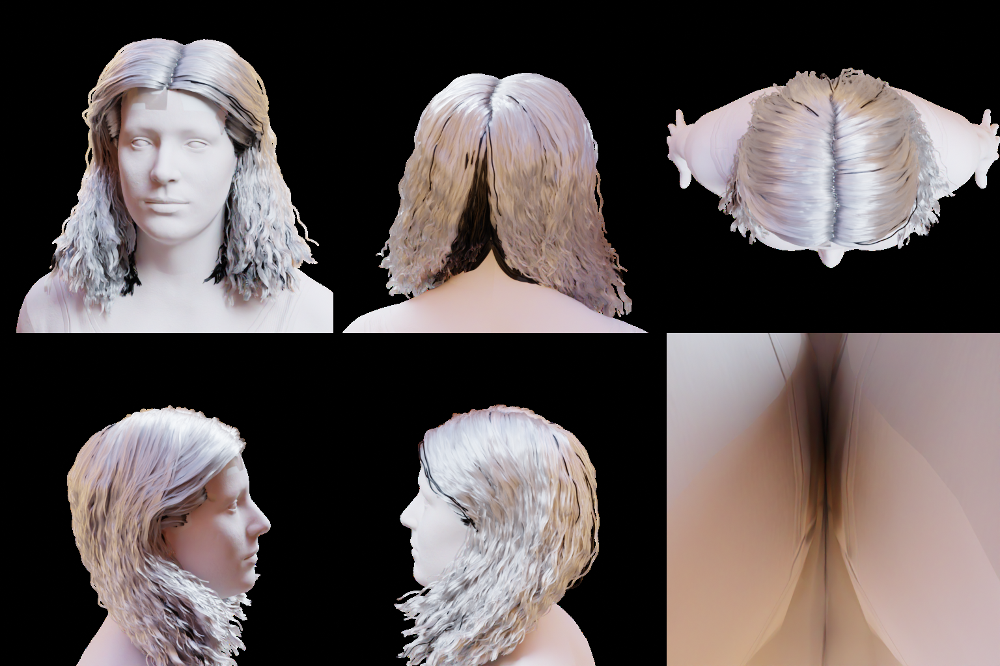

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/render_info.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/scalp_grid_rgb.jpg
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/template_notebook_color_matrix.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_original/render/template_notebook_color_matrix.npz
fm_original: rendered in 20.1 s (gpu), 0 strands left out
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/template_notebook_c

00:00.289  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:05.401  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
00:07.950  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/front.png'
00:10.001  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/_multiview_tmp.png'
00:11.830  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/_multiview_tmp.png'
00:13.703  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/_multi

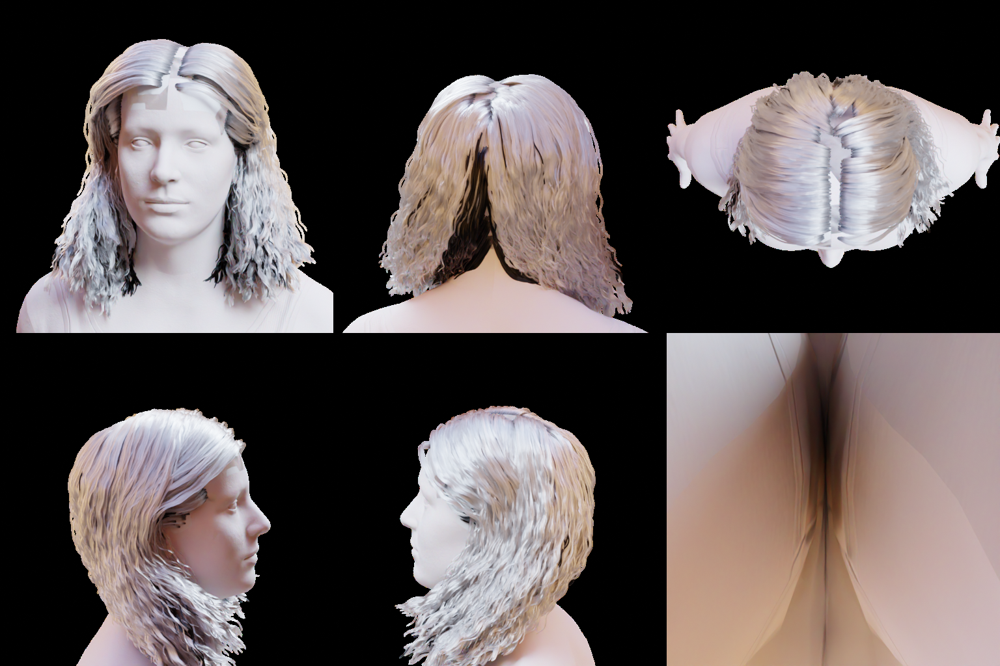

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/ignore_mask.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/render_info.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/scalp_grid_rgb.jpg
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/template_notebook_color_matrix.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1/render/template_notebook_color_matrix.npz
fm_clip1: rendered in 19.4 s (gpu), 9464 strands left out
wrote /home/kyh/Desktop/

00:00.251  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:05.866  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
00:08.491  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/front.png'
00:10.553  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/_multiview_tmp.png'
00:12.415  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/_multiview_tmp.png'
00:14.304  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_

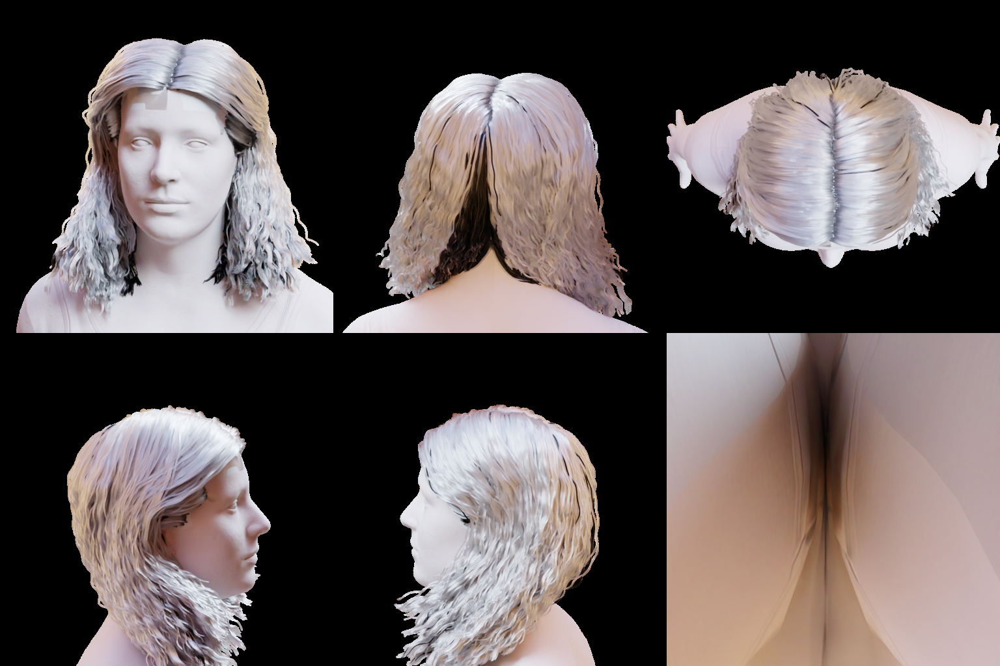

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/render_info.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/scalp_grid_rgb.jpg
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/template_notebook_color_matrix.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip1_restored/render/template_notebook_color_matrix.npz
fm_clip1_restored: rendered in 20.1 s (gpu), 0 strands left out
wrote /home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025

00:00.293  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:05.754  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
00:08.322  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/front.png'
00:10.400  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/_multiview_tmp.png'
00:12.261  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/_multiview_tmp.png'
00:14.160  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/_multi

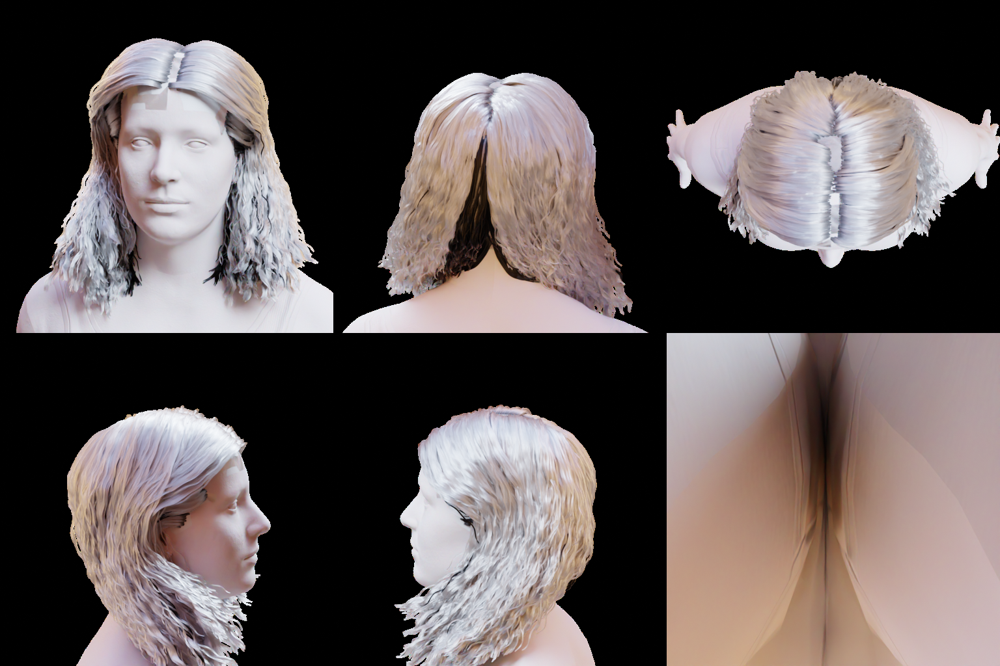

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/ignore_mask.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/render_info.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/scalp_grid_rgb.jpg
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/template_notebook_color_matrix.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2/render/template_notebook_color_matrix.npz
fm_clip2: rendered in 19.9 s (gpu), 3358 strands left out
wrote /home/kyh/Desktop/

00:00.252  blend            | Read blend: "/home/kyh/Desktop/P76154862/NCKU_3D_hair_reconstruction/inference/assets/blender_vis_base_v26_with_shrinkwrap_full_base.blend"
00:05.858  cycles           | WARNING HIPEW initialization failed: Error opening HIP dynamic library
00:08.476  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/front.png'
00:10.556  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/_multiview_tmp.png'
00:12.419  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/_multiview_tmp.png'
00:14.381  render           | Saved: '/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_

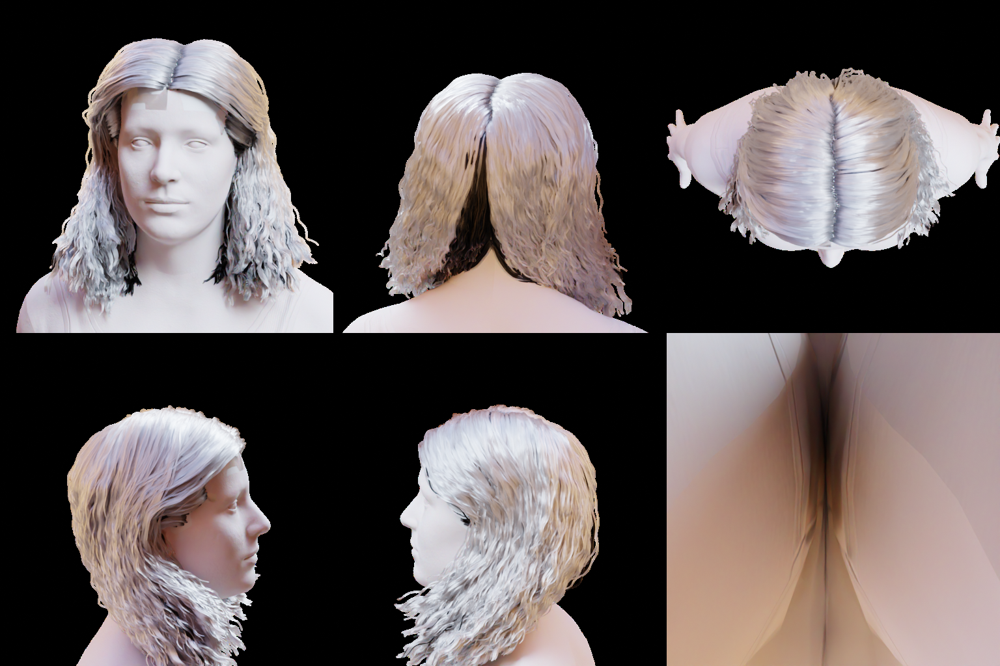

/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/render_info.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/scalp_grid.npz
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/scalp_grid_rgb.jpg
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/template_notebook_color_matrix.json
/home/kyh/Desktop/P76154862/highlighting/generate_from_3D_models/contour_algo_test/data/divergence_clip/case_0025/fm_clip2_restored/render/template_notebook_color_matrix.npz
fm_clip2_restored: rendered in 20.3 s (gpu), 0 strands left out


In [9]:
RENDER_TIMES = {}


def render_result(name):
    r = RESULTS[name]
    out_dir = os.path.join(OUT, name, "render")
    png = os.path.join(out_dir, "front_multiview.png")
    if os.path.exists(png) and not OVERWRITE_RENDER:
        return png
    # back to the full npz strand order (the render template is aligned with it)
    root_uv = common.load_hairstyle(NPZ, root_uv_only=True)["root_uv"]
    state = np.zeros(root_uv.shape[0], bool); ignore = np.ones(root_uv.shape[0], bool)
    state[hair["strand_idx"]] = r.strand_mask
    ignore[hair["strand_idx"]] = r.hidden if r.hidden is not None else False
    t0 = time.time()
    with _render_device(RENDER_DEVICE):
        ma_render.render_strand_mask(
            state, out_dir, root_uv=root_uv, strands_npz=NPZ, dataset_path=bench["dataset_path"],
            template_dir=out_dir, grid_size=case["grid_n"], ignore_mask=ignore if ignore.any() else None,
            base_color=np.array(common.BASE_RGB), highlight_color=np.array(common.HIGHLIGHT_RGB),
            source="contour_algo_test/divergence_clip_test.ipynb")
    RENDER_TIMES[name] = round(time.time() - t0, 1)
    common.write_json(dict(seconds=RENDER_TIMES[name], device=RENDER_DEVICE, strands_left_out=int(ignore.sum()),
                           finished=common.now_str()), os.path.join(out_dir, "render_info.json"))
    print(f"{name}: rendered in {RENDER_TIMES[name]} s ({RENDER_DEVICE}), {int(ignore.sum())} strands left out")
    return png if os.path.exists(png) else None


def show_renders(names):
    for n in names:
        png = os.path.join(OUT, n, "render", "front_multiview.png")
        if not os.path.exists(png):
            print(f"{n}: no render"); continue
        img = plt.imread(png)
        fig = plt.figure(figsize=(18, 18 * img.shape[0] / img.shape[1]))
        plt.imshow(img); plt.axis("off")
        plt.title(f"{n}   grid score mean {SCORES[n]['grid_score']['mean_all']:.4f}"); plt.show()


if RENDER:
    for n in ALL:
        render_result(n)

### FM: original / clip1 / clip2

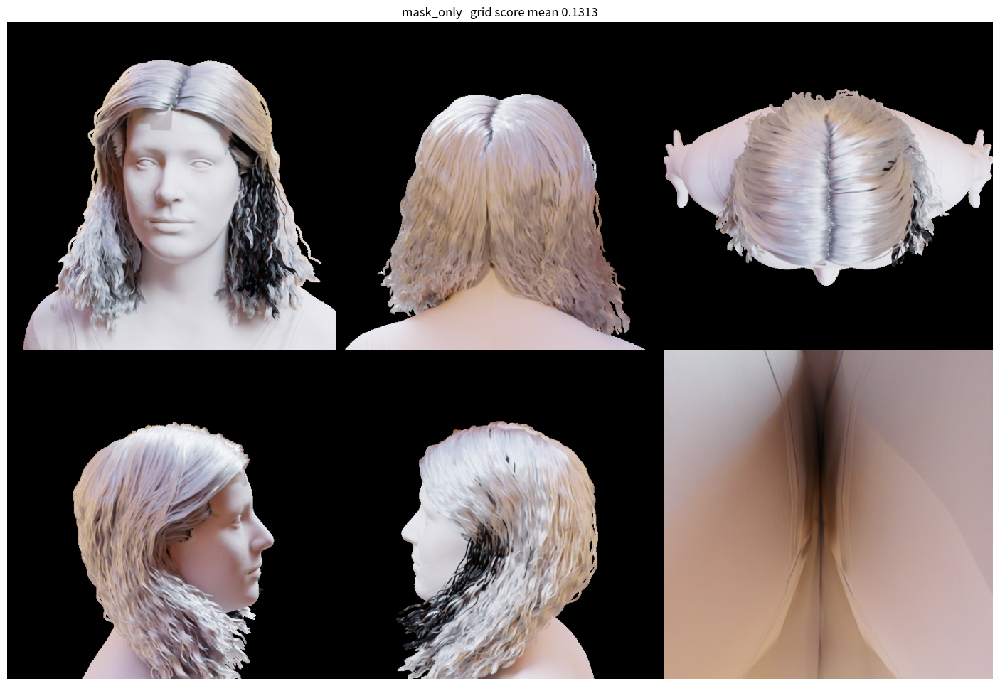

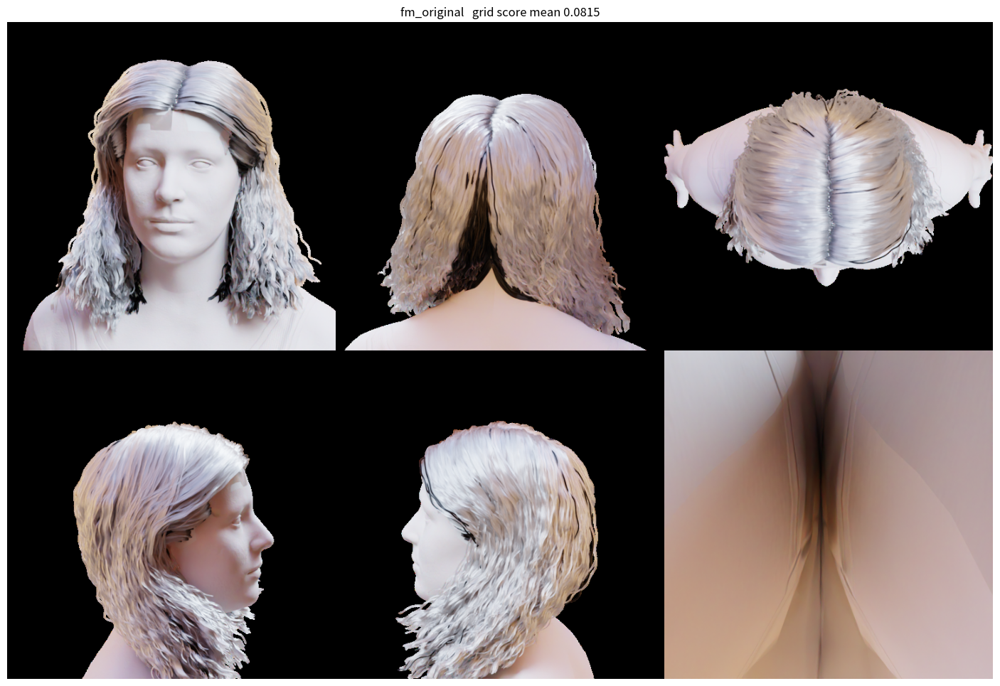

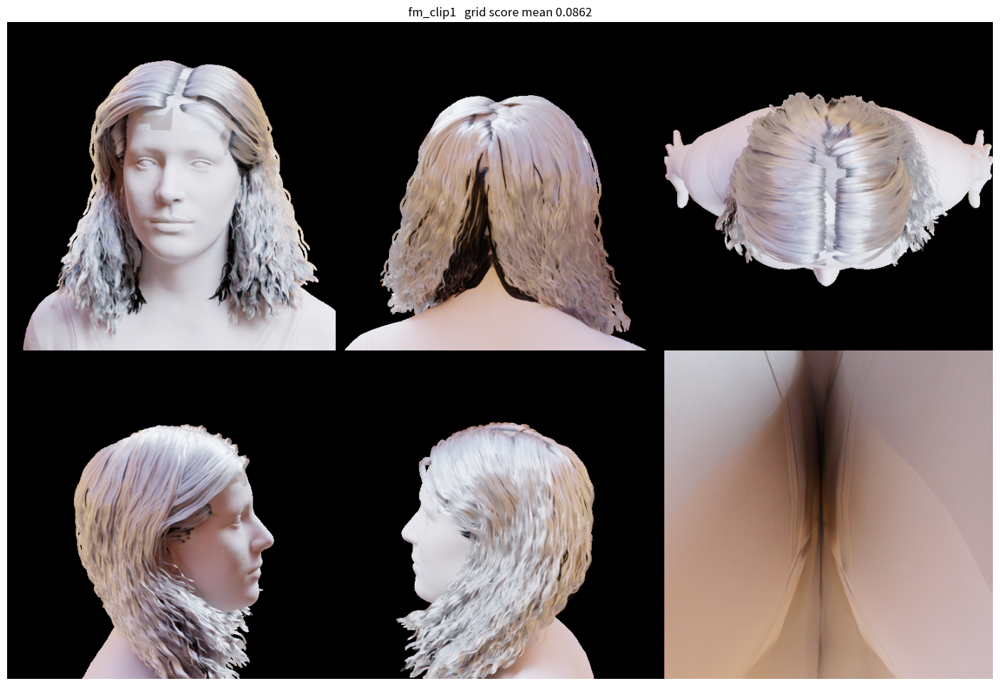

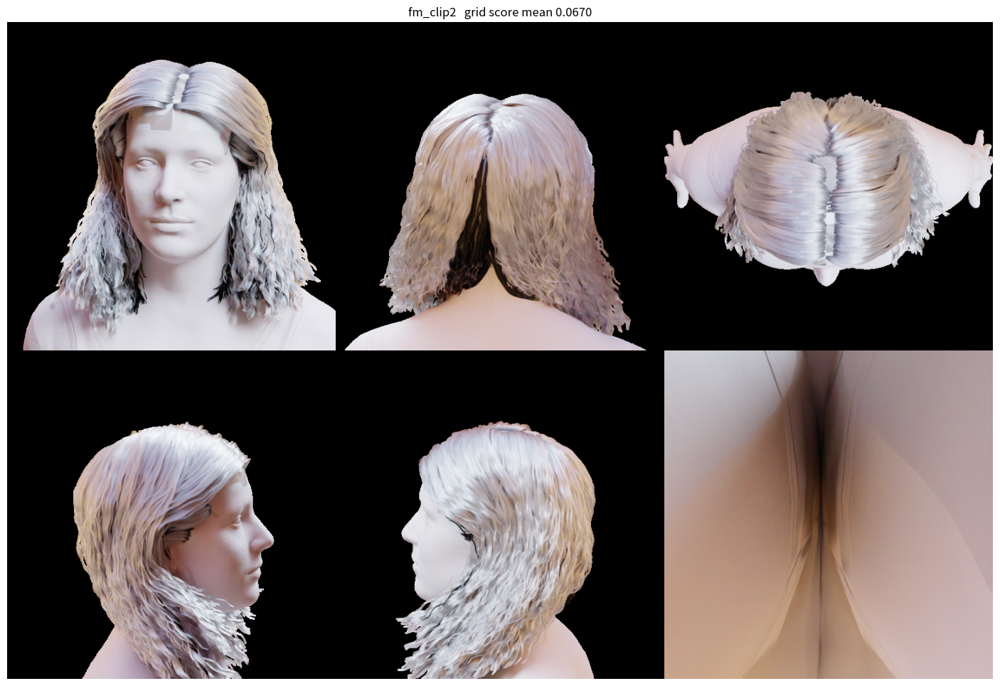

In [10]:
show_renders(["mask_only", "fm_original", "fm_clip1", "fm_clip2"])

### Strands added back (compared with the original FM)

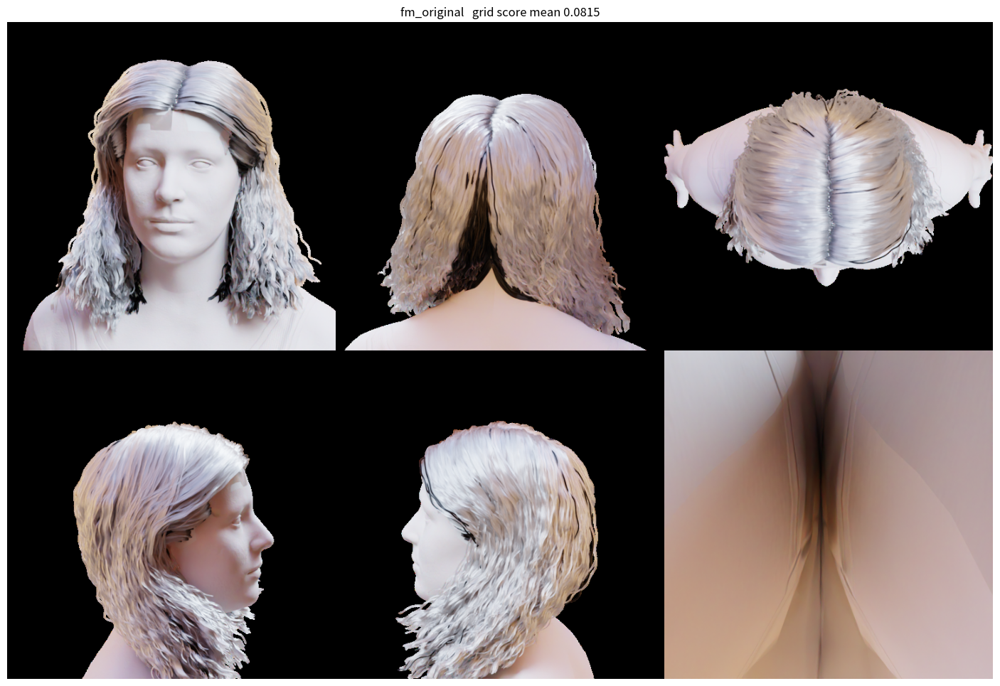

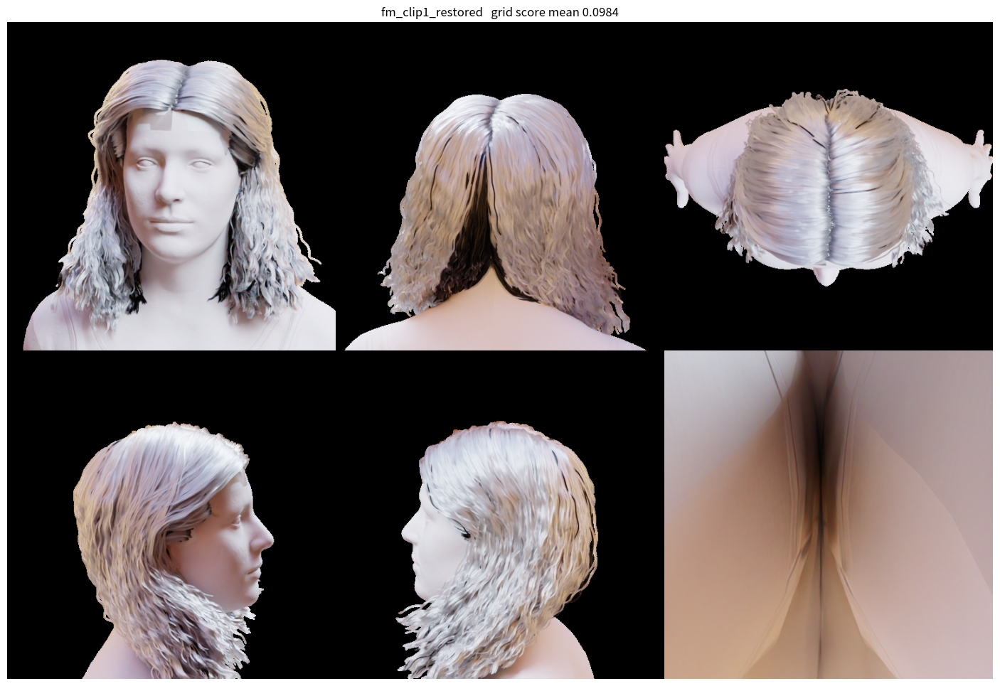

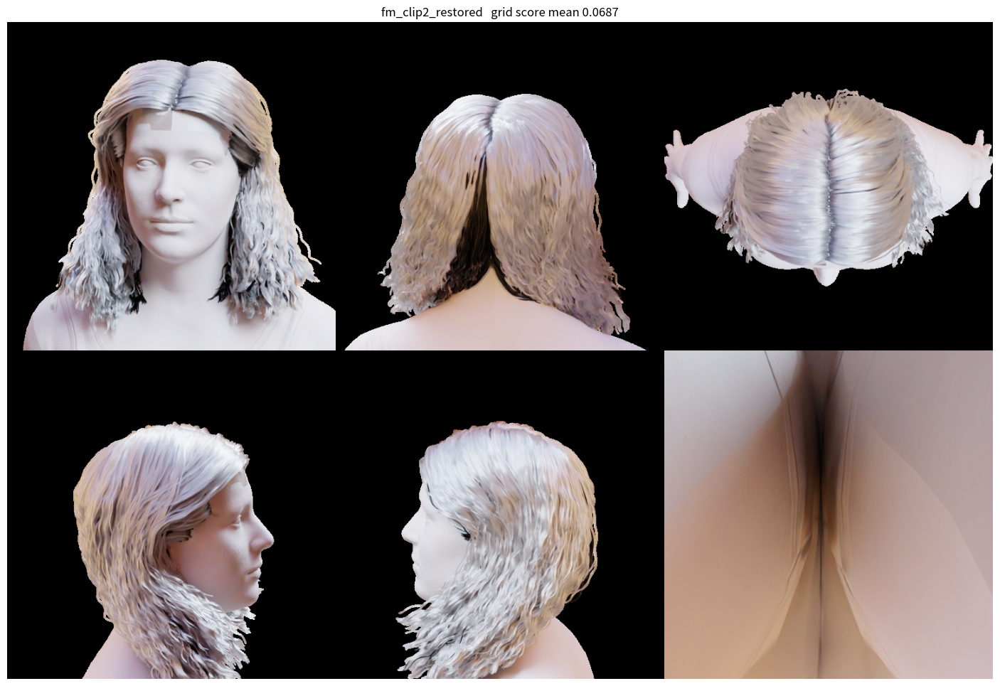

In [11]:
show_renders(["fm_original", "fm_clip1_restored", "fm_clip2_restored"])